# QFAMES numerical experiments
Run the three experiments and inspect their summary tables and six figures.

Open this notebook from the repository root and select a Python environment with `requirements-notebook.txt` installed. Run the cells in order, or use **Run All**.

By default, all three action selectors are set to `"plot"` to regenerate figures from saved data without simulation. Full runs can take considerable time and memory.


In [13]:
from pathlib import Path
import csv
import html
import json
import os
import re
import signal
import subprocess
import sys

from IPython.display import HTML, Image, Markdown, display

# Usually no change is needed. Set an absolute path if Jupyter starts elsewhere.
PROJECT_ROOT = None

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates
                 if (p / "experiments/common.py").is_file()
                 and (p / "qfames/core.py").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("Open this notebook from the repository, or set PROJECT_ROOT.")
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
    if not (ROOT / "experiments/common.py").is_file():
        raise FileNotFoundError("PROJECT_ROOT is not a QFAMES repository.")

def display_path(path):
    return Path(os.path.relpath(path, ROOT)).as_posix()


def display_text(text):
    # Child processes may print absolute paths; change only their displayed text.
    text = text.replace(sys.executable, "python")
    for prefix in {str(ROOT), ROOT.as_posix()}:
        text = re.sub(re.escape(prefix) + r"[\\/]", "", text, flags=re.IGNORECASE)
        text = re.sub(re.escape(prefix), ".", text, flags=re.IGNORECASE)
    return text.replace("\\", "/")


print("Project: .")
print("Python version:", sys.version.split()[0])


Project: .
Python version: 3.12.15


## Run settings

- `MODE`: `"paper"` uses the JSON configurations; `"quick"` uses small smoke-test sweeps.
- Experiment actions: `"run"` computes or resumes, `"plot"` regenerates figures, and `"view"` displays existing figures. Missing saved data is skipped for `"plot"` and `"view"`. Eigenvalue and multiplicity also skip saved configurations that differ from the requested settings.
- `RESUME = True` reuses compatible completed trials. For changed settings or a fresh run, choose a new `RUN_NAME`.
- `WORKERS` controls parallel processes; `TRIALS` and `SEED` override configuration defaults. `OUTPUTS` selects each experiment directory.

Settings are in `configs/`. Avoid running the notebook and a terminal job against the same output directory simultaneously.


In [14]:
MODE = "paper"
WORKERS = 2
RESUME = True
TRIALS = None
SEED = None
RUN_NAME = None

EXPERIMENTS = ("eigenvalue", "multiplicity", "observable")
CONFIGS = {name: ROOT / "configs" / f"{name}.json" for name in EXPERIMENTS}

if MODE not in {"paper", "quick"}:
    raise ValueError("MODE must be paper or quick.")
if not isinstance(WORKERS, int) or WORKERS < 1:
    raise ValueError("WORKERS must be a positive integer.")
if TRIALS is not None and (not isinstance(TRIALS, int) or TRIALS < 1):
    raise ValueError("TRIALS must be None or a positive integer.")
if SEED is not None and (not isinstance(SEED, int) or SEED < 0):
    raise ValueError("SEED must be None or a nonnegative integer.")
if RUN_NAME is not None and (not RUN_NAME or RUN_NAME in {".", ".."}
                             or "/" in RUN_NAME or "\\" in RUN_NAME):
    raise ValueError("RUN_NAME must be a single folder name.")

OUTPUT_ROOT = ROOT / "results" / (RUN_NAME or MODE)
print(f"Mode: {MODE}; workers: {WORKERS}")
print("Output:", display_path(OUTPUT_ROOT))

# Independent output directories; changing one does not redirect other experiments.
OUTPUTS = {
    "eigenvalue": OUTPUT_ROOT / "eigenvalue",
    "multiplicity": OUTPUT_ROOT / "multiplicity",
    "observable": OUTPUT_ROOT / "observable",
}


Mode: paper; workers: 2
Output: results/paper


## Execution and display helpers
Experiments run in separate processes using the kernel's Python interpreter, including on Windows. Interrupting a cell stops its process tree and retains completed trial rows; summaries and figures may still be incomplete.

Experiment errors stop execution. Resume requires unchanged configurations, source hashes, and NumPy/SciPy versions; otherwise use a new output directory.


In [15]:
FIGURES = {
    "eigenvalue": ["eigenvalue_error_vs_state_count", "eigenvalue_error_vs_total_time"],
    "multiplicity": ["multiplicity_singular_values_vs_state_count_independent",
                     "multiplicity_singular_values_vs_state_count_shared"],
    "observable": ["observable_error_vs_state_count", "observable_error_vs_total_time"],
}


def execute(command):
    env = os.environ.copy()
    env["PYTHONUNBUFFERED"] = "1"
    env["PYTHONIOENCODING"] = "utf-8"
    options = {"creationflags": subprocess.CREATE_NEW_PROCESS_GROUP} if os.name == "nt" else {"start_new_session": True}
    display_command = ["python"] + [display_path(part) if isinstance(part, Path) else str(part)
                                    for part in command[1:]]
    print("Running:", " ".join(display_command), flush=True)
    process = subprocess.Popen(
        [str(part) for part in command], cwd=ROOT, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace", bufsize=1, **options,
    )
    try:
        for line in process.stdout:
            print(display_text(line), end="", flush=True)
        returncode = process.wait()
        if returncode:
            raise subprocess.CalledProcessError(returncode, display_command)
    except BaseException:
        if process.poll() is None:
            if os.name == "nt":
                subprocess.run(["taskkill", "/PID", str(process.pid), "/T", "/F"],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False)
            else:
                try:
                    os.killpg(process.pid, signal.SIGTERM)
                except ProcessLookupError:
                    pass
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                if os.name != "nt":
                    try:
                        os.killpg(process.pid, signal.SIGKILL)
                    except ProcessLookupError:
                        pass
                else:
                    process.kill()
                process.wait()
        raise
    finally:
        process.stdout.close()


def spectral_settings_match(name):
    if name not in {"eigenvalue", "multiplicity"}:
        return True
    meta = json.loads((OUTPUTS[name] / "metadata.json").read_text(encoding="utf-8"))
    current = json.loads(CONFIGS[name].read_text(encoding="utf-8"))
    if MODE == "quick":
        current.update(L_values=[5, 6, 8] if name == "multiplicity" else [4, 6, 8], N_values=[40, 80, 160], fixed_N=80, trials=4)
    if TRIALS is not None:
        current["trials"] = TRIALS
    if SEED is not None:
        current["seed"] = SEED
    if meta["config"] != current or meta.get("quick") != (MODE == "quick"):
        print(f"Existing results use outdated settings; rerun {name}")
        print("Saved settings:", meta["config"])
        print("Requested settings:", current)
        return False
    return True


def run_experiment(name, action="plot"):
    if action not in {"run", "plot", "view"}:
        raise ValueError(f"{name}: action must be run, plot, or view.")
    directory = OUTPUTS[name]
    if action in {"plot", "view"}:
        missing = [str(directory / filename) for filename in ("metadata.json", "summary.csv")
                   if not (directory / filename).is_file()]
        if missing:
            print(f"{name}: no saved data in {display_path(directory)}; skipped. Explicitly select action=run to simulate.")
            return False
    if action in {"plot", "view"} and not spectral_settings_match(name):
        return False
    if action == "view":
        return True
    if action == "plot":
        execute([sys.executable, "-u", "-m", "qfames.plotting", directory])
        return True
    command = [sys.executable, "-u", "-m", f"experiments.{name}_scaling",
               "--config", CONFIGS[name], "--output", directory, "--workers", WORKERS]
    if MODE == "quick":
        command.append("--quick")
    if TRIALS is not None:
        command += ["--trials", TRIALS]
    if SEED is not None:
        command += ["--seed", SEED]
    if RESUME:
        command.append("--resume")
    execute(command)
    return True


def show_file(path):
    link = Path(os.path.relpath(path, Path.cwd())).as_posix()
    display(HTML(f'<a href="{html.escape(link, quote=True)}" target="_blank">'
                 f'{html.escape(display_path(path))}</a>'))


def show_results(name):
    directory = OUTPUTS[name]
    required = [directory / "metadata.json", directory / "summary.csv"]
    missing = [display_path(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError("Run the experiment first. Missing: " + ", ".join(missing))
    if not spectral_settings_match(name):
        return
    meta = json.loads(required[0].read_text(encoding="utf-8"))
    with required[1].open(newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    cfg = meta["config"]
    display(Markdown(f"### {name.capitalize()} results"))
    print("Saved run:", display_path(directory))
    print(f"Saved settings: T={cfg['T']}, sigma={cfg['sigma']}, trials/point={cfg['trials']}, seed={cfg['seed']}")
    if meta.get("quick"):
        display(Markdown("**Smoke-test data: not paper results.**"))
    observed = sum(int(r["trials"]) for r in rows)
    failed = sum(int(r["failed"]) for r in rows)
    ns = [cfg["fixed_N"]] if name == "multiplicity" else cfg["N_values"]
    expected = len(cfg["L_values"]) * len(ns) * cfg["trials"] * len(meta.get("sampling_schemes", ["independent"] if name == "multiplicity" else ["independent", "shared"]))
    print(f"Trials in saved summary: {observed}/{expected}; failures: {failed}")
    if observed != expected:
        display(Markdown("**Partial summary: complete or resume this run before using its figures.**"))
    print("Summary and images reflect their last saved versions; an active run may be newer.")
    columns = ["scheme", "N", "L", "trials", "failed", "error_q90", "mean_total_time"]
    if name == "multiplicity":
        columns = ["scheme", "N", "L", "trials", "failed"] + [f"sv_{c}_{k}" for c in range(2) for k in range(1, 6)]
        print("sv_<cluster>_<k> columns contain mean normalized singular values s_k/L evaluated at the exact cluster centers.")
    def formatted(value):
        try:
            return f"{float(value):.5g}"
        except ValueError:
            return value
    header = "".join(f"<th>{html.escape(c)}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(formatted(row[c]))}</td>" for c in columns) + "</tr>" for row in rows)
    display(HTML(f'<div style="overflow-x:auto"><table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'))
    figures = directory / "figures"
    for stem in FIGURES[name]:
        if name == "multiplicity" and "singular_values" in stem:
            scheme = stem.rsplit("_", 1)[-1]
            if not any(r.get("scheme", "independent") == scheme for r in rows):
                print(f"No {scheme} data; singular-value figure skipped.")
                continue
        png = figures / f"{stem}.png"
        if not png.is_file():
            raise FileNotFoundError(f"Missing {display_path(png)}; set this experiment action to 'plot' to regenerate figures.")
        display(Markdown(f"**{stem.replace('_', ' ')}**"))
        display(Image(filename=str(png), width=653 if "singular_values" in stem else 322))
        pdf = png.with_suffix(".pdf")
        if pdf.is_file():
            show_file(pdf)
    for filename in ("metadata.json", "trials.csv", "summary.csv"):
        show_file(directory / filename)


## 1. Eigenvalue error scaling
Two figures show error versus state count L=R and sampled total evolution time. The cost plot compares three N values for both sampling schemes.


Running: python -u -m qfames.plotting results/paper/eigenvalue
Figures saved to results/paper/eigenvalue/figures


### Eigenvalue results

Saved run: results/paper/eigenvalue
Saved settings: T=200.0, sigma=6.0, trials/point=100, seed=42
Trials in saved summary: 5400/5400; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.


scheme,N,L,trials,failed,error_q90,mean_total_time
independent,50,2,100,0,0.0012138,45030
independent,50,4,100,0,0.00058719,1.8002e+05
independent,50,8,100,0,0.00027499,7.2147e+05
independent,50,12,100,0,0.00018772,1.627e+06
independent,50,20,100,0,0.00012482,4.5078e+06
independent,50,32,100,0,6.3784e-05,1.155e+07
independent,50,50,100,0,4.4559e-05,2.8204e+07
independent,50,70,100,0,3.4067e-05,5.528e+07
independent,50,100,100,0,2.3597e-05,1.1281e+08
independent,200,2,100,0,0.00049327,1.8079e+05


**eigenvalue error vs state count**

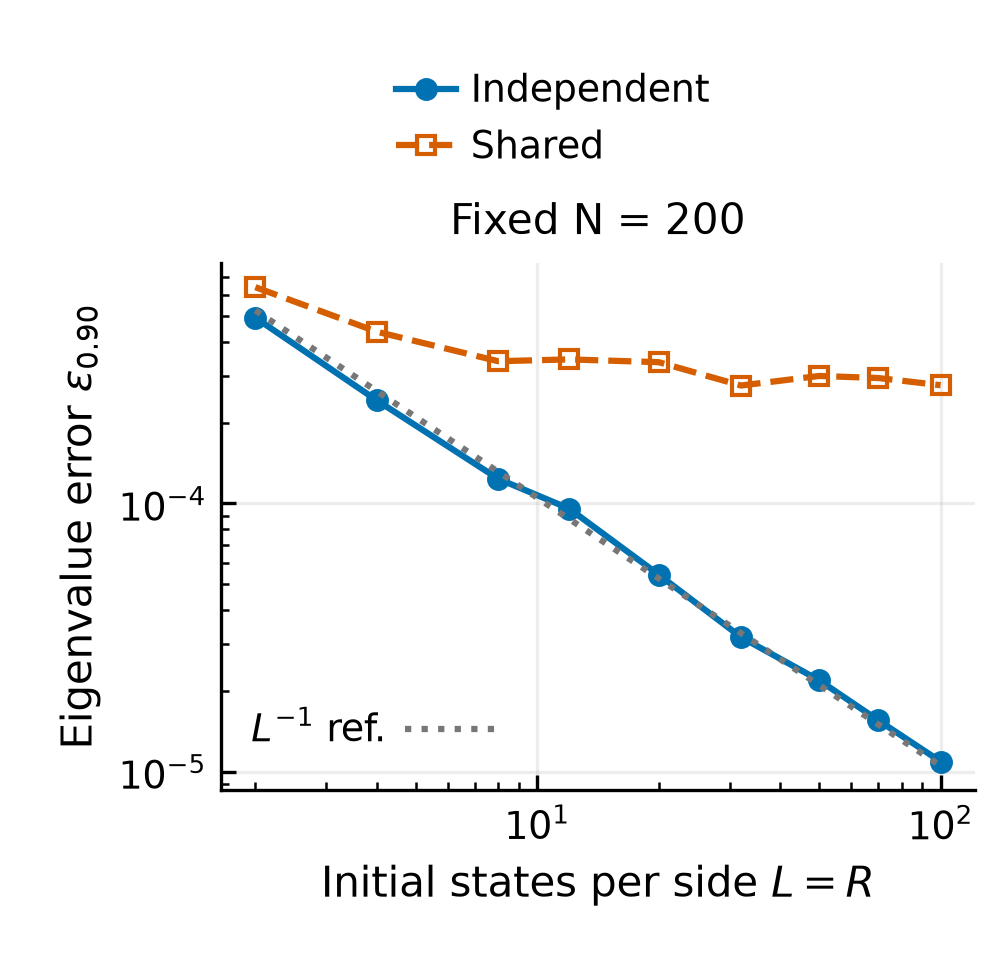

**eigenvalue error vs total time**

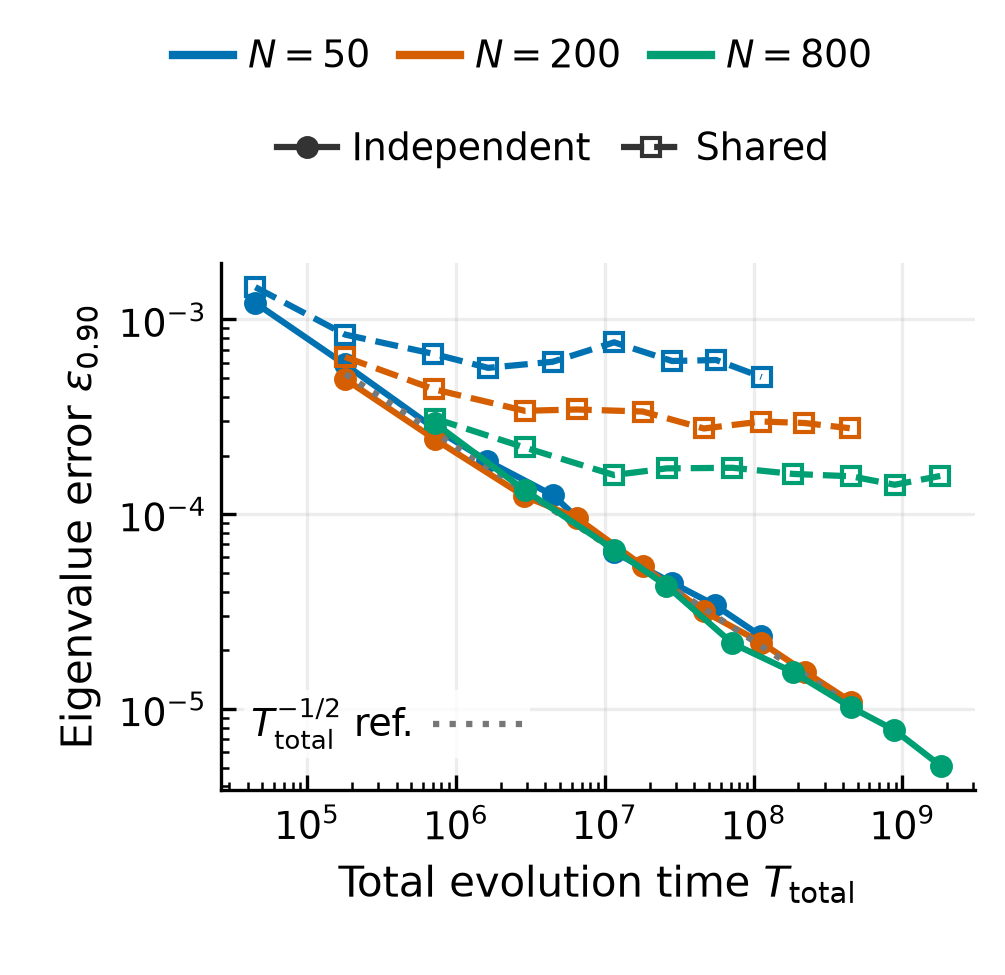

In [16]:
EIGENVALUE_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("eigenvalue", EIGENVALUE_ACTION):
    show_results("eigenvalue")


## 2. Multiplicity structure
Separate two-panel figures show independent and shared sampling. Each plots mean normalized singular values s1/L through s5/L at exact centers 0 and 0.02, with target multiplicities 2 and 1. No peak search is performed.


Running: python -u -m qfames.plotting results/paper/multiplicity
Figures saved to results/paper/multiplicity/figures


### Multiplicity results

Saved run: results/paper/multiplicity
Saved settings: T=150.0, sigma=6.0, trials/point=50, seed=42
Trials in saved summary: 900/900; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.
sv_<cluster>_<k> columns contain mean normalized singular values s_k/L evaluated at the exact cluster centers.


scheme,N,L,trials,failed,sv_0_1,sv_0_2,sv_0_3,sv_0_4,sv_0_5,sv_1_1,sv_1_2,sv_1_3,sv_1_4,sv_1_5
independent,30,5,50,0,0.31631,0.16614,0.034355,0.01907,0.0070206,0.25382,0.05243,0.034221,0.019293,0.0089538
independent,30,8,50,0,0.30281,0.18413,0.036219,0.02768,0.020363,0.25247,0.046735,0.036904,0.028702,0.021715
independent,30,12,50,0,0.29413,0.19456,0.032264,0.027134,0.022897,0.25029,0.041086,0.034866,0.030644,0.026463
independent,30,16,50,0,0.28619,0.2112,0.029799,0.025754,0.022904,0.25213,0.036982,0.032659,0.029252,0.02642
independent,30,24,50,0,0.27781,0.21675,0.025632,0.023479,0.021614,0.25277,0.031075,0.028288,0.026175,0.024408
independent,30,32,50,0,0.27912,0.21586,0.02272,0.021176,0.019902,0.25038,0.02771,0.025798,0.024317,0.022955
independent,30,50,50,0,0.2719,0.22729,0.018698,0.017771,0.017044,0.25086,0.022425,0.021248,0.020334,0.019648
independent,30,70,50,0,0.26635,0.23146,0.016051,0.015476,0.014882,0.25002,0.019293,0.018499,0.017899,0.017316
independent,30,100,50,0,0.264,0.23288,0.013648,0.013236,0.012884,0.25006,0.016216,0.01574,0.015369,0.015042
shared,30,5,50,0,0.31662,0.1671,0.034386,0.012579,0.0034031,0.25395,0.053652,0.025399,0.011592,0.0029965


**multiplicity singular values vs state count independent**

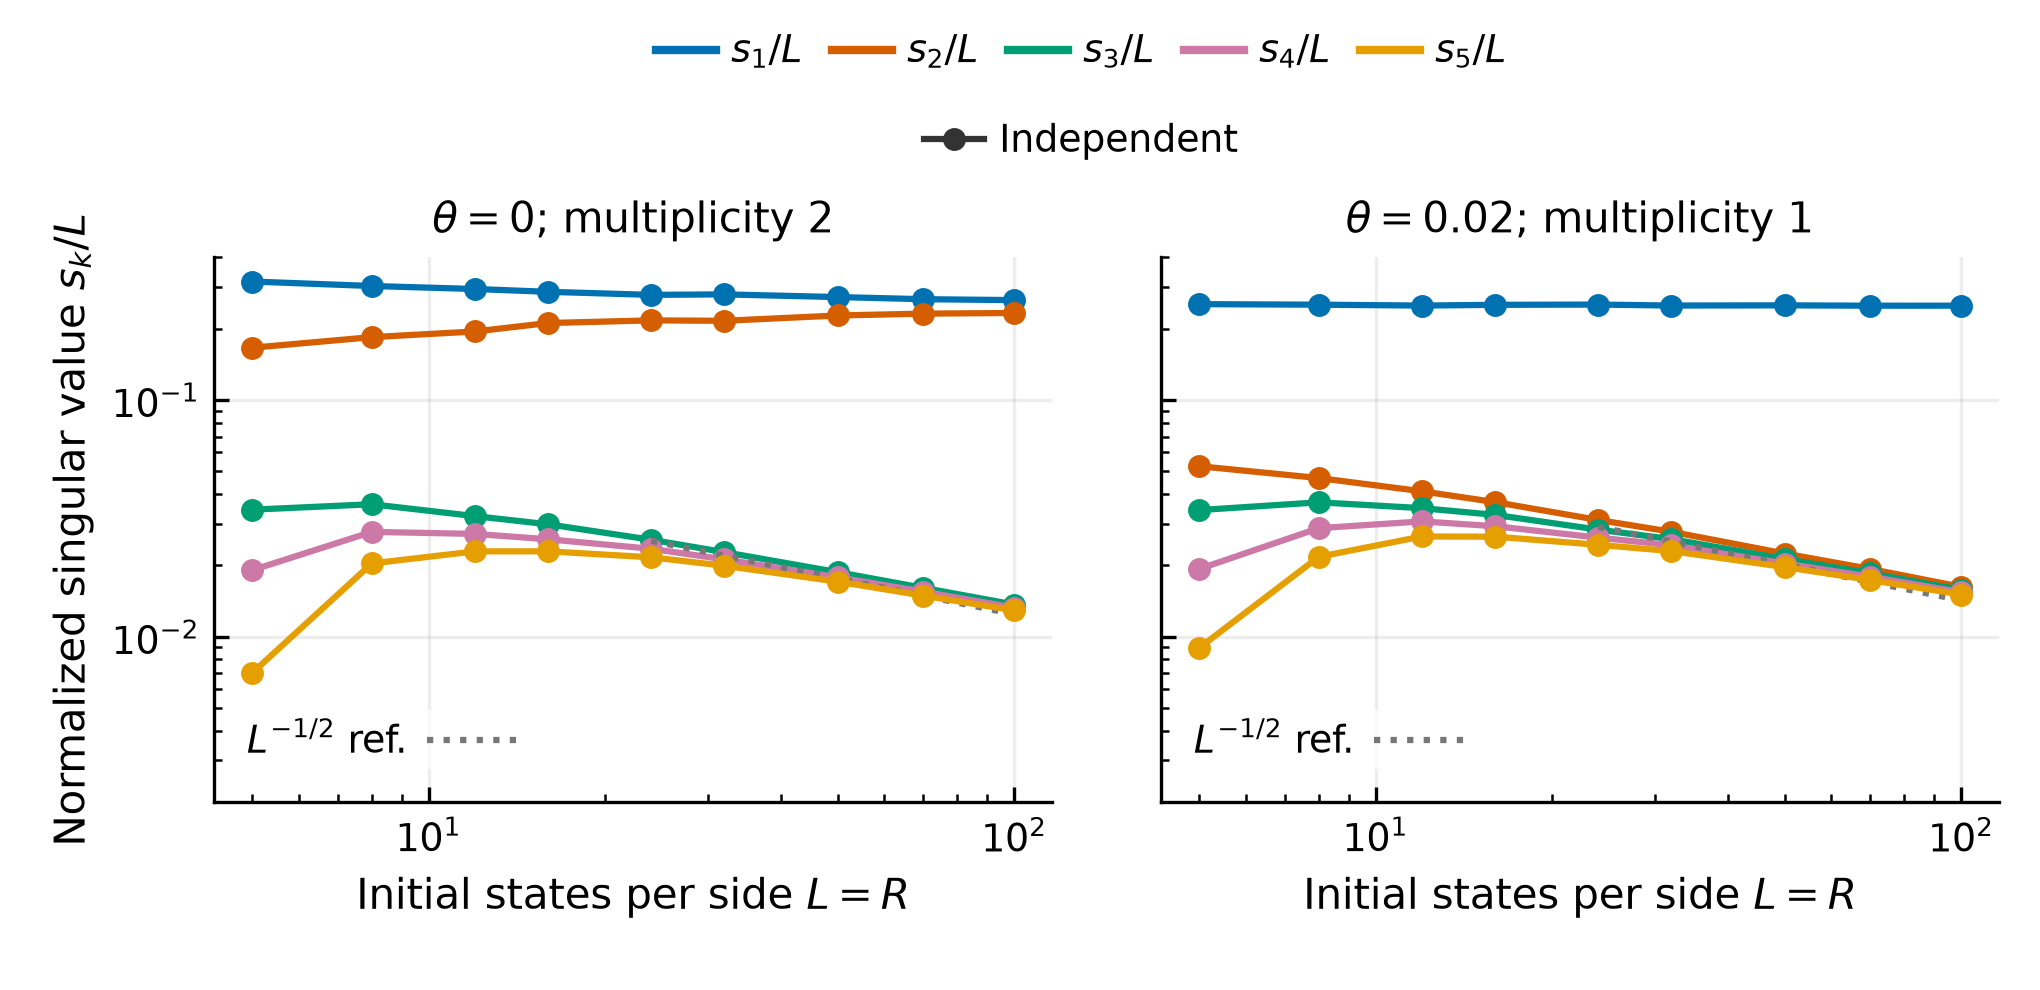

**multiplicity singular values vs state count shared**

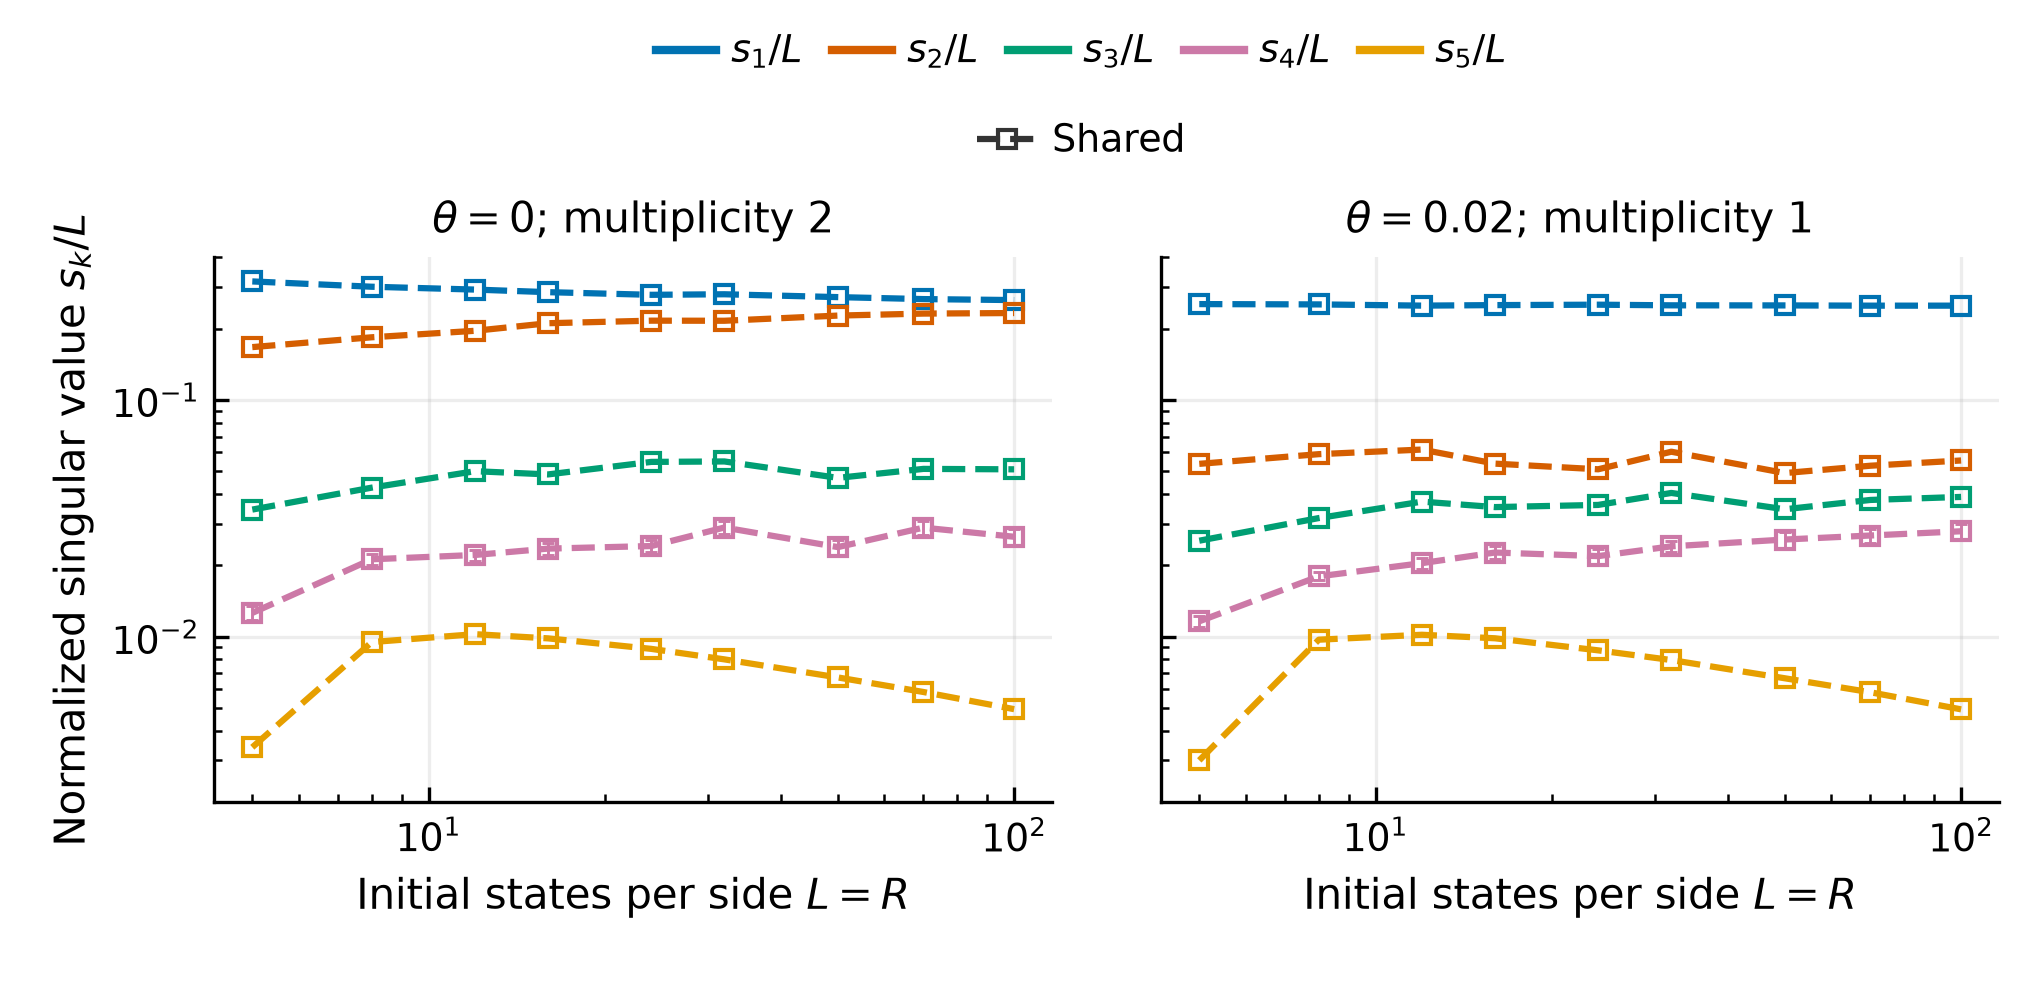

In [17]:
MULTIPLICITY_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("multiplicity", MULTIPLICITY_ACTION):
    show_results("multiplicity")


## 3. Observable error scaling
Two figures compare independent and shared sampling versus state count and sampled total evolution time. Cost includes spectral-data acquisition and both observable evolution legs.


Running: python -u -m qfames.plotting results/paper/observable
Figures saved to results/paper/observable/figures


### Observable results

Saved run: results/paper/observable
Saved settings: T=50.0, sigma=6.0, trials/point=100, seed=42
Trials in saved summary: 4800/4800; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.


scheme,N,L,trials,failed,error_q90,mean_total_time
independent,200,3,100,0,0.073765,2.4547e+05
independent,200,5,100,0,0.04453,6.8086e+05
independent,200,8,100,0,0.028244,1.7448e+06
independent,200,12,100,0,0.016703,3.9201e+06
independent,200,16,100,0,0.014146,6.9734e+06
independent,200,24,100,0,0.010425,1.5688e+07
independent,200,32,100,0,0.0071948,2.7885e+07
independent,200,50,100,0,0.0040586,6.8098e+07
independent,500,3,100,0,0.045729,6.13e+05
independent,500,5,100,0,0.025984,1.7029e+06


**observable error vs state count**

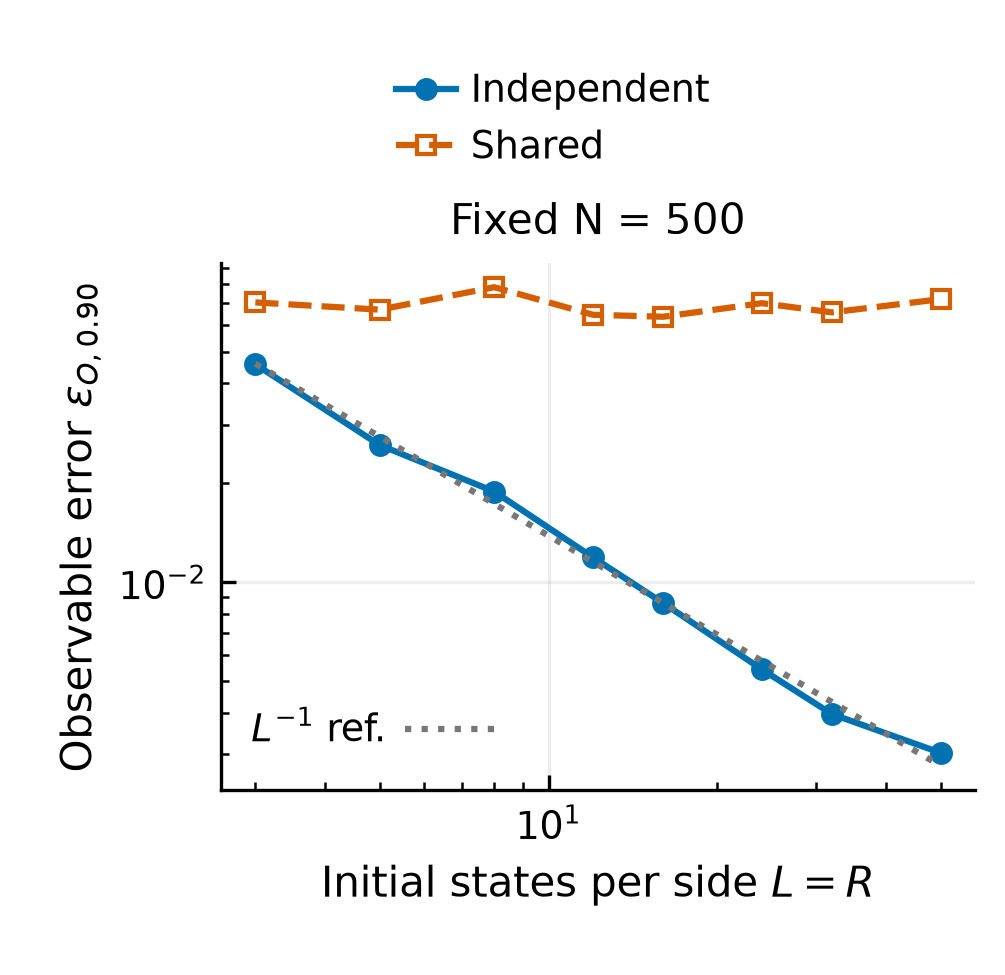

**observable error vs total time**

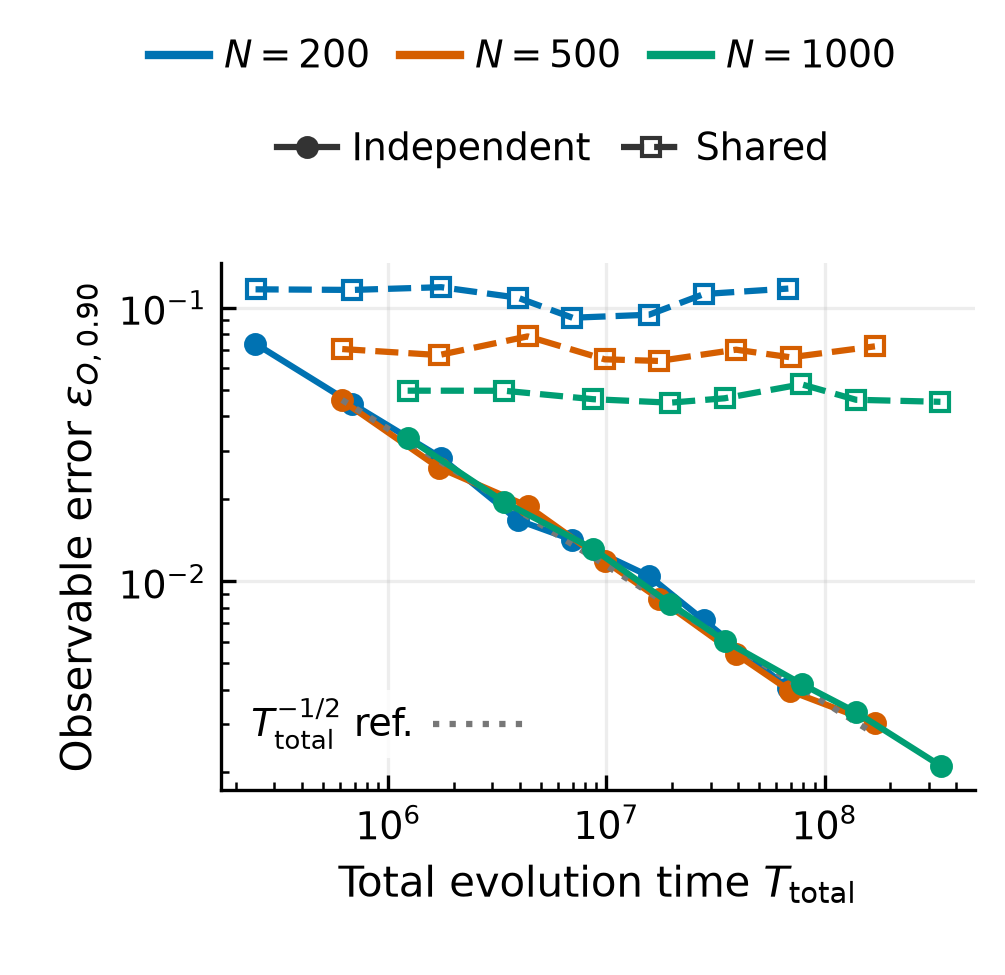

In [18]:
OBSERVABLE_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("observable", OBSERVABLE_ACTION):
    show_results("observable")


## Saved results
Each experiment directory contains `metadata.json`, `trials.csv`, `summary.csv`, and PDF/PNG figures. Default full-run outputs are in `results/paper/`.

Use `"plot"` to regenerate figures after editing `qfames/plotting.py`, or `"view"` to display existing figures. Save the notebook to retain inline tables and figures. Quick-run figures are marked as smoke tests.
